# Concrete Compressive Strength Prediction Using ANN

## Project Objective

This project investigates the use of an Artificial Neural Network (ANN) to predict the compressive strength of concrete based on its mix composition and curing age.

## Dataset

The project uses the UCI Concrete Compressive Strength dataset, which contains 1,030 experimental observations.

## Methodology

1. Data loading and exploratory data analysis
2. Data preprocessing and feature scaling
3. ANN model training
4. Model evaluation using MAE, RMSE, and R²


## Scope and Limitations

The model is intended for educational and exploratory analysis. Its predictions are not a substitute for laboratory testing, approved concrete mix design, or engineering validation.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

dataset = (
    "https://archive.ics.uci.edu/"
    "ml/machine-learning-databases/"
    "concrete/compressive/Concrete_Data.xls"
)

df = pd.read_excel(dataset)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

df.head()

Dataset shape: (1030, 9)

Column names:
['Cement (component 1)(kg in a m^3 mixture)', 'Blast Furnace Slag (component 2)(kg in a m^3 mixture)', 'Fly Ash (component 3)(kg in a m^3 mixture)', 'Water  (component 4)(kg in a m^3 mixture)', 'Superplasticizer (component 5)(kg in a m^3 mixture)', 'Coarse Aggregate  (component 6)(kg in a m^3 mixture)', 'Fine Aggregate (component 7)(kg in a m^3 mixture)', 'Age (day)', 'Concrete compressive strength(MPa, megapascals) ']


,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


In [2]:
# Clean and shorten the column names for easier access and modeling
new_column_names = {
    'Cement (component 1)(kg in a m^3 mixture)': 'cement',
    'Blast Furnace Slag (component 2)(kg in a m^3 mixture)': 'blast_furnace_slag',
    'Fly Ash (component 3)(kg in a m^3 mixture)': 'fly_ash',
    'Water  (component 4)(kg in a m^3 mixture)': 'water',
    'Superplasticizer (component 5)(kg in a m^3 mixture)': 'superplasticizer',
    'Coarse Aggregate  (component 6)(kg in a m^3 mixture)': 'coarse_aggregate',
    'Fine Aggregate (component 7)(kg in a m^3 mixture)': 'fine_aggregate',
    'Age (day)': 'age',
    'Concrete compressive strength(MPa, megapascals) ': 'compressive_strength'
}

df = df.rename(columns=new_column_names)

# Quick overview of the cleaned dataset and missing values
print("Renamed Column Names")
print(df.columns.tolist())


print("\nMissing Values Summary")
print(df.isnull().sum())

display(df.head())

Renamed Column Names
['cement', 'blast_furnace_slag', 'fly_ash', 'water', 'superplasticizer', 'coarse_aggregate', 'fine_aggregate', 'age', 'compressive_strength']

Missing Values Summary
cement                  0
blast_furnace_slag      0
fly_ash                 0
water                   0
superplasticizer        0
coarse_aggregate        0
fine_aggregate          0
age                     0
compressive_strength    0
dtype: int64


,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,compressive_strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


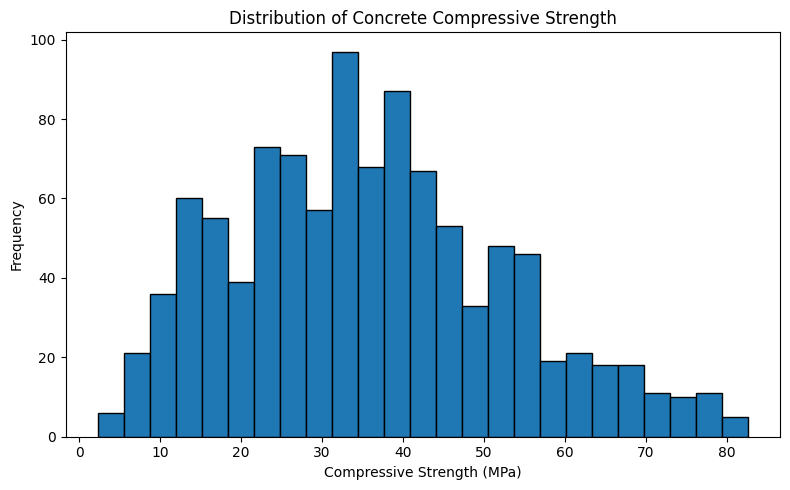

In [3]:
plt.figure(figsize=(8, 5))

plt.hist(
    df['compressive_strength'],
    bins=25,
    edgecolor='black'
)

plt.xlabel('Compressive Strength (MPa)')
plt.ylabel('Frequency')
plt.title('Distribution of Concrete Compressive Strength')

plt.tight_layout()
plt.show()

In [4]:
##Data Preparation

# Separate input features and target variable

x = df.drop('compressive_strength', axis=1)
y = df['compressive_strength']

print("Input features shape:", x.shape)
print("Target variable shape:", y.shape)
print("\nInput features:")
print(x.columns.tolist())

Input features shape: (1030, 8)
Target variable shape: (1030,)

Input features:
['cement', 'blast_furnace_slag', 'fly_ash', 'water', 'superplasticizer', 'coarse_aggregate', 'fine_aggregate', 'age']


In [5]:
#Train-test-split

from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.3,random_state=2)
print("Training features:", x_train.shape)
print("Testing features:", x_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

Training features: (721, 8)
Testing features: (309, 8)
Training targets: (721,)
Testing targets: (309,)


In [6]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

print("Training data shape:", x_train_scaled.shape)
print("Testing data shape:", x_test_scaled.shape)

Training data shape: (721, 8)
Testing data shape: (309, 8)


In [7]:
import tensorflow
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense

tensorflow.keras.utils.set_random_seed(42)

model = Sequential()
model.add(Dense(64,activation='relu',input_dim=8))
model.add(Dense(32,activation='relu'))

model.add(Dense(1,activation='linear'))
model.compile(optimizer='Adam',loss='mean_squared_error',metrics=['mean_absolute_error'])

history = model.fit(x_train_scaled, y_train, batch_size=32, epochs=200, validation_split=0.2, callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=10,restore_best_weights=True)])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 6s 67ms/step - loss: 1581.1128 - mean_absolute_error: 35.8705 - val_loss: 1425.5057 - val_mean_absolute_error: 34.3909
Epoch 2/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 1510.3053 - mean_absolute_error: 34.9076 - val_loss: 1346.3160 - val_mean_absolute_error: 33.2589
Epoch 3/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 1415.7480 - mean_absolute_error: 33.5937 - val_loss: 1237.5676 - val_mean_absolute_error: 31.6539
Epoch 4/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - loss: 1283.9067 - mean_absolute_error: 31.6995 - val_loss: 1087.4891 - val_mean_absolute_error: 29.3315
Epoch 5/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - loss: 1106.8323 - mean_absolute_error: 29.0153 - val_loss: 896.3285 - val_mean_absolute_error: 26.2121
Epoch 6/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 889.9714 - mean_absolute_error: 25.4872 - val_loss: 676.4345 - val_mean_absolute_error: 22.3148
Epoch 7/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - l

In [8]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_pred = model.predict(x_test_scaled).flatten()

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE:", round(mae, 2), "MPa")
print("RMSE:", round(rmse, 2), "MPa")
print("R² Score:", round(r2, 3))

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
MAE: 4.51 MPa
RMSE: 5.8 MPa
R² Score: 0.874


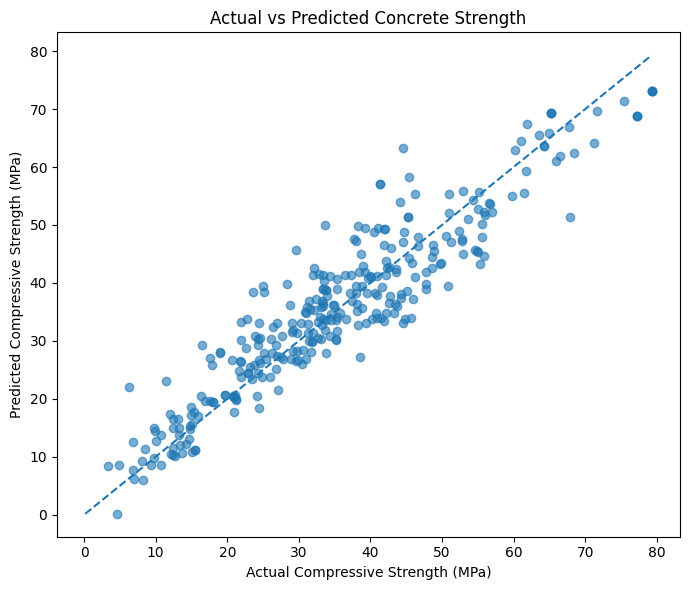

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 6))

plt.scatter(y_test, y_pred, alpha=0.6)

# Ideal predictions fall on this line
minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle='--'
)

plt.xlabel('Actual Compressive Strength (MPa)')
plt.ylabel('Predicted Compressive Strength (MPa)')
plt.title('Actual vs Predicted Concrete Strength')
plt.tight_layout()
plt.show()

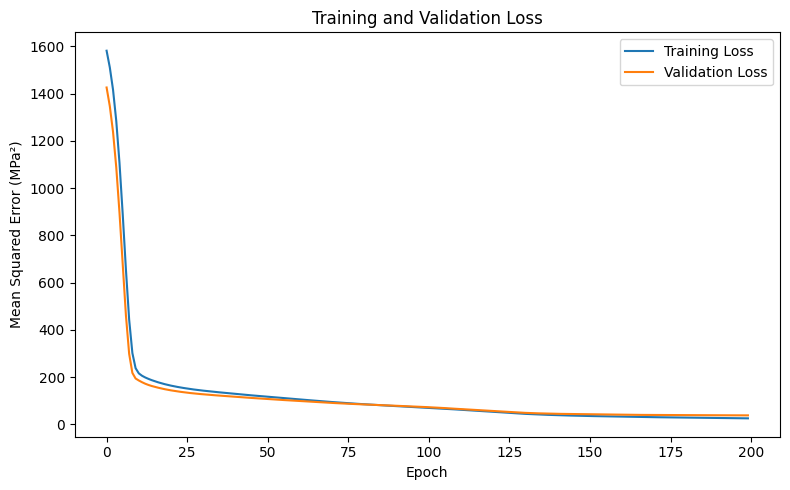

In [10]:
#Training performance

plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Mean Squared Error (MPa²)')
plt.title('Training and Validation Loss')
plt.legend()
plt.tight_layout()
plt.show()

### 10. Conclusion

An Artificial Neural Network (ANN) was developed using TensorFlow/Keras to predict concrete compressive strength from eight input features describing the concrete mixture and curing age. The dataset was divided into training and testing subsets, and the input features were standardized using statistics learned from the training data.

#### Model Performance

The model was evaluated on the held-out test set using three regression metrics:

* **Mean Absolute Error (MAE):** 4.51 MPa
* **Root Mean Squared Error (RMSE):** 5.8 MPa
* **Coefficient of Determination (R²):** 0.874

The results indicate that the model captured a substantial proportion of the variation in compressive strength within the test dataset. The actual-versus-predicted plot and training curves provide additional insight into prediction accuracy and model learning.

#### Limitations & Future Work

* **Data Dependability:** Model performance depends on the dataset and train-test split.
* **Generalization:** Further validation on independent datasets would be needed before considering application to unfamiliar concrete mixtures.
* **Safety Warning:** The predictions are for educational and research purposes and do not replace laboratory testing or approved concrete mix-design procedures.